Loading the Faster R-CNN model...
Running object detection...
Visualizing results:


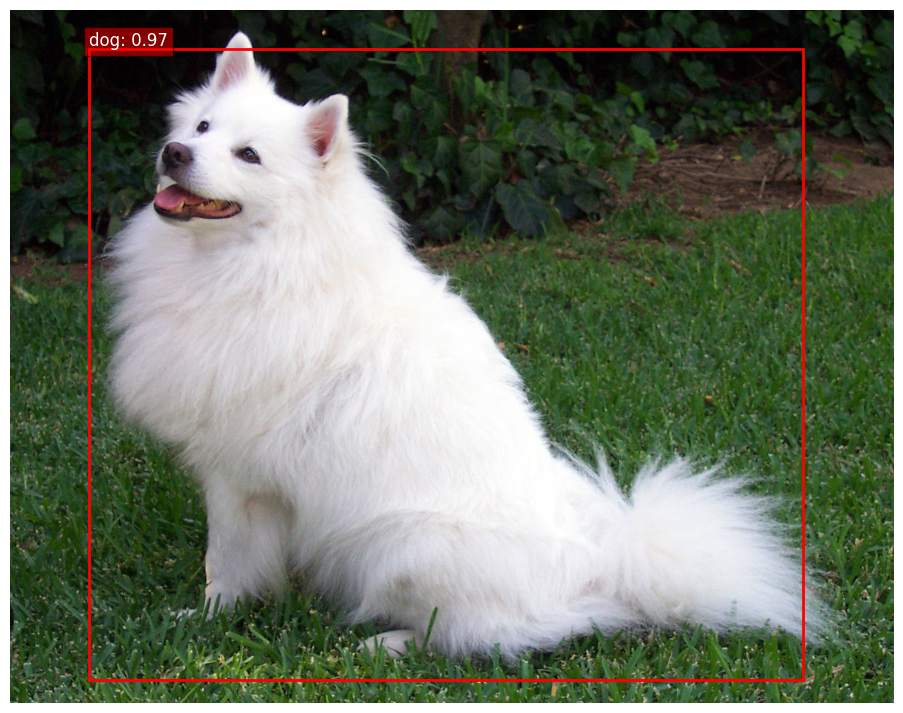

In [10]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
import torchvision.transforms as T
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from PIL import Image
import urllib.request

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_detection_model():
    weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    model = fasterrcnn_resnet50_fpn(weights=weights)
    model.to(device)
    model.eval()
    return model, weights.meta["categories"]

def detect_objects(image_path, model, threshold=0.5):
    img = Image.open(image_path).convert("RGB")
    transform = T.Compose([T.ToTensor()])
    img_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        prediction = model(img_tensor)[0]

    keep = prediction['scores'] > threshold
    boxes = prediction['boxes'][keep].cpu().numpy()
    labels = prediction['labels'][keep].cpu().numpy()
    scores = prediction['scores'][keep].cpu().numpy()

    return img, boxes, labels, scores

def visualize_detections(img, boxes, labels, scores, categories):
    fig, ax = plt.subplots(1, figsize=(12, 9))
    ax.imshow(img)

    for box, label, score in zip(boxes, labels, scores):
        x_min, y_min, x_max, y_max = box
        rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                 linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        class_name = categories[label]
        ax.text(x_min, y_min - 5, f"{class_name}: {score:.2f}",
                color='white', fontsize=12, bbox=dict(facecolor='red', alpha=0.5))

    plt.axis('off')
    plt.show()

def calculate_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interArea = max(0, xB - xA) * max(0, yB - yA)
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    iou = interArea / float(boxAArea + boxBArea - interArea)
    return iou

if __name__ == "__main__":
    image_url = 'https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg'
    image_path = 'sample_image.jpg'
    print("Downloading sample image...")
    urllib.request.urlretrieve(image_url, image_path)

    print("Loading the Faster R-CNN model...")
    model, categories = load_detection_model()

    print("Running object detection...")
    img, boxes, labels, scores = detect_objects(image_path, model, threshold=0.8)

    print("Visualizing results:")
    visualize_detections(img, boxes, labels, scores, categories)

Visualizing dummy segmentation overlay:


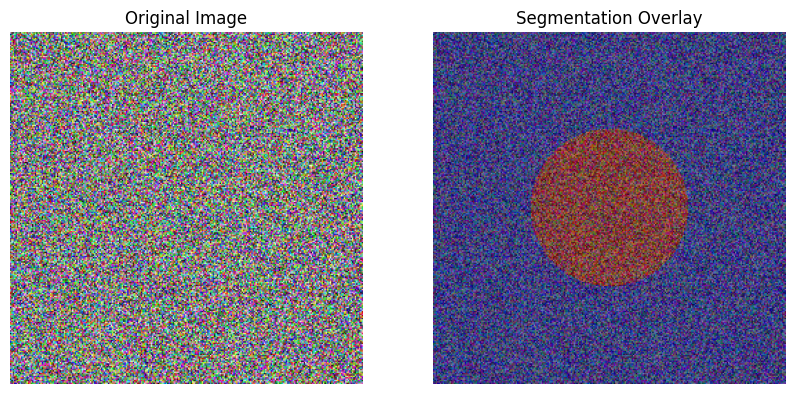

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()
        self.down1 = DoubleConv(in_channels, 64)
        self.down2 = DoubleConv(64, 128)
        self.down3 = DoubleConv(128, 256)
        self.down4 = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.up_conv1 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.up_conv2 = DoubleConv(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.up_conv3 = DoubleConv(128, 64)

        self.out_conv = nn.Conv2d(64, out_channels, 1)

    def forward(self, x):
        x1 = self.down1(x)
        x2 = self.down2(F.max_pool2d(x1, 2))
        x3 = self.down3(F.max_pool2d(x2, 2))
        x4 = self.down4(F.max_pool2d(x3, 2))

        d1 = self.up1(x4)
        d1 = torch.cat([x3, d1], dim=1)
        d1 = self.up_conv1(d1)

        d2 = self.up2(d1)
        d2 = torch.cat([x2, d2], dim=1)
        d2 = self.up_conv2(d2)

        d3 = self.up3(d2)
        d3 = torch.cat([x1, d3], dim=1)
        d3 = self.up_conv3(d3)

        return self.out_conv(d3)

def dice_score(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    intersection = (pred * target).sum(dim=(2,3))
    union = pred.sum(dim=(2,3)) + target.sum(dim=(2,3))

    dice = (2. * intersection + smooth) / (union + smooth)
    return dice.mean().item()

def visualize_segmentation(img_tensor, mask_tensor):
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    mask = mask_tensor.squeeze().cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img)
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(img)
    axes[1].imshow(mask, alpha=0.5, cmap='jet')
    axes[1].set_title('Segmentation Overlay')
    axes[1].axis('off')
    plt.show()

if __name__ == "__main__":
    dummy_image = torch.rand(3, 256, 256)

    x = torch.linspace(-1, 1, 256)
    y = torch.linspace(-1, 1, 256)
    xx, yy = torch.meshgrid(x, y, indexing='ij')
    dummy_mask = (xx**2 + yy**2 < 0.2).float().unsqueeze(0)

    print("Visualizing dummy segmentation overlay:")
    visualize_segmentation(dummy_image, dummy_mask)